In [ ]:
# # ---- Cell 1: setup (re-run after every Colab runtime reset) ----
# from google.colab import drive
# drive.mount('/content/drive')

# BASE = '/content/drive/MyDrive/Colab Notebooks/MAR'

# import sys, glob, re
# sys.path.insert(0, BASE)

# %pip install -q nlopt

# # Find R packages referenced in src/*.py and install the missing ones
# from rpy2.robjects.packages import importr, isinstalled
# from rpy2.robjects.vectors import StrVector

# R_BASE = {'base', 'utils', 'stats', 'methods', 'graphics', 'grDevices', 'datasets', 'tools'}
# needed = set()
# for f in glob.glob(f'{BASE}/src/*.py'):
#     txt = open(f).read()
#     needed |= set(re.findall(r'importr\(\s*[\'"]([\w.]+)[\'"]', txt))
#     needed |= set(re.findall(r'(?:library|require)\(\s*[\'"]?([\w.]+)[\'"]?\s*\)', txt))

# missing = sorted(p for p in needed - R_BASE if not isinstalled(p))
# print("R packages needed:", sorted(needed - R_BASE))
# print("Missing, installing:", missing)

# if missing:
#     utils = importr('utils')
#     utils.chooseCRANmirror(ind=1)
#     utils.install_packages(StrVector(missing))

In [2]:

import numpy as np
import pandas as pd
import torch

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error

from collections.abc import Callable
from typing import Optional

from joblib import Parallel, delayed

#import nlopt





from src.parametric_estimation import ParametricEstimation
from src.motivating_example import MotivatingExample
from src.ampute_mar import AmputeMAR
from src.data_generator import DataGenerator

During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 


### Choose parameters

In [72]:
n = 2000
d = 20
eps = 1e-2
methods = ['generation', 'imputation', 'complete-case', 'nmmipw', 'gmm_ipw'] #['generation', 'imputation', 'complete', 'complete-case', 'nmmipw', 'gmm_ipw']
motexp = True
Ycol = 0 # may be "new" if use_motexp=False, otherwise 0
distr= 'Logistic'
# distr = 'gaussian_mixture'


### PARAMS FOR OTHER DISTRIBUTIONS
if not motexp:
    n_pat = 5
    if distr=='gaussian_mixture':
        k=20
        mu0 = torch.rand((k, d)) * 2 - 1 # [-1, 1]
        sigma0 = torch.rand((k, d)) * 2 # (0, 2)
        pi0 = torch.rand(k) + 0.1
        pi0 = pi0 / pi0.sum()
        data_generator =DataGenerator(distr=distr,mu=mu0, sigma=sigma0, pi=pi0)
    else:
        data_generator = DataGenerator(distr=distr)

### Set up classes

In [60]:
class DataGeneratorXY():
    def __init__(
        self,
        coef_true: torch.tensor,
        sample_error: Callable[[int], torch.tensor],
        data_generator_X: DataGenerator
    ):
        self.sample_X = data_generator_X.sample_truth
        self.sample_error = sample_error
        self.coef_true = coef_true

    def sample_truth(
        self,
        n:int,
        d:int
    ):
        # generate X based on DataGenerator
        X = self.sample_X(n, d-1)
        # generate Y as linear combination + error
        self.coef_true = self.coef_true.to(dtype=X.dtype) 
        Y = self.coef_true[0] + X @ self.coef_true[1:] + self.sample_error(n).to(dtype=X.dtype) 
        # concatenate X and Y
        # (Y in first column because ampute function keeps last column fully observed)
        return torch.cat([Y[:, None], X], dim=1)

class XYM_gen():
    def __init__(
        self,
        n,
        d,
        data_generator,
        n_pat
    ):
        self.n = n
        self.d = d
        self.data_generator = data_generator
        self.amputemar = AmputeMAR(n, d, n_pat, seed=1)

    def get_X(self):
        return self.data_generator.sample_truth(self.n, self.d)

    def get_M(self, X):
        _, M = self.amputemar.ampute(X)
        return M
        

In [73]:
if motexp:
    XM_generator = MotivatingExample(type='mar', n=n, d=d)
    coef_true = torch.tensor([0, 0.7] + [0]*(d-2))
    Ycol=0
    n_pat = 3
else:
    # create a new column for Y which really follows a linear regression of the other variables
    if Ycol == "new":
        coef_true = torch.tensor(np.random.choice([0, 0.5, -0.5, 2, -2], size=d+1)) #d-1 + intercept
        dg = DataGeneratorXY(coef_true=coef_true, sample_error=lambda n: np.sqrt(0.5)*torch.randn(n), data_generator_X=data_generator)
        Ycol = 0
        d_eff = d+1
    # otherwise we regress one of the X columns (Ycol) given all others 
    elif type(Ycol) == int and Ycol in np.arange(-d, d):
        if distr == "Logistic" and Ycol == 0:
            coef_true = torch.tensor([0] + [0.7] + [0]*(d-2))
        else:
            coef_true = None
        dg = data_generator
        d_eff = d
    else:
        raise ValueError("Ycol needs to be set to 'new' or an integer between -d (counting backwards) and d")

    XM_generator = XYM_gen(n, d_eff, dg, n_pat)
        

In [62]:
coef_true

tensor([0.0000, 0.7000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000])

### Run experiments

In [46]:
def job(
        XM_generator,
        eps: float = None, # clamping scale
        Ycol:int = None, # which variable
        methods: list = None
    ):
    X = XM_generator.get_X()
    M = XM_generator.get_M(X)
    pe = ParametricEstimation(X=X, M=M)

    # generate test data to compute regression accuracy
    test_data = XM_generator.get_X()
    Xtest = test_data[:, np.arange(test_data.shape[1]) != Ycol % test_data.shape[1]]
    Ytest = test_data[:, Ycol]

    out = {}
    for method in methods:
        lin_reg = pe.linear_regression(Ycol=Ycol, method=method, eps=eps)
        coef = np.concatenate(([lin_reg.intercept_], lin_reg.coef_))
        err = mean_squared_error(lin_reg.predict(Xtest), Ytest)
        out[method] = (coef, err)
    return out

In [47]:
B=50

results = Parallel(n_jobs=5)(
    delayed(job)(
        XM_generator=XM_generator,
        eps=eps,
        Ycol=Ycol,
        methods=methods
    )
    for _ in range(B)
)

     
results

During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C"

Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast metho

[{'generation': (array([-0.06292623,  0.16925895,  0.17784745,  0.15797502,  0.02830185,
           0.01864266,  0.04089173, -0.06036846, -0.03207668, -0.03133651,
          -0.03914127,  0.01067278,  0.05535425, -0.02169907,  0.01600251,
          -0.03889826, -0.03523358,  0.02216171,  0.01785142, -0.01151101],
         dtype=float32),
   2.325833254092495),
  'imputation': (array([-0.04885097,  0.27351705,  0.18339888,  0.12708716,  0.0014084 ,
          -0.00792083,  0.03698367, -0.03140744, -0.01956137,  0.02684348,
          -0.01867605,  0.0146025 , -0.04532013, -0.0074236 ,  0.02444261,
           0.00440748, -0.03060714, -0.00539059,  0.03815818, -0.03228805]),
   2.1016108599091363),
  'complete-case': (array([ 0.03440562,  0.6510427 ,  0.03866166,  0.0143279 ,  0.01497353,
           0.08339837, -0.1206955 ,  0.09589578, -0.00979956,  0.00904232,
          -0.07327787,  0.02526945, -0.01204401, -0.00073374,  0.0629922 ,
          -0.04537135, -0.0676117 ,  0.08750198, -0.060

In [74]:
results = np.load(f"results/regression_3_patterns_50_B_motexp_True_gaussian_mixture_0_Ycol.npy", allow_pickle=True)
# results = np.load(f"results/regression_{n_pat}_patterns_{B}_B_motexp_{motexp}_{distr}_{Ycol}_Ycol.npy", allow_pickle=True)

In [79]:
coef_est = {m: [r[m][0][:2] for r in results] for m in methods}
mse      = {m: [r[m][1] for r in results] for m in methods}

In [49]:
np.save(f"results/regression_{n_pat}_patterns_{B}_B_motexp_{motexp}_{distr}_{Ycol}_Ycol.npy", results)

### Plot function

In [66]:
method_names = {'generation': "Generation",
               'imputation': "Imputation",
               'complete-case': "Fully obs.",
               'nmmipw': "NMMIPW",
               'gmm_ipw': "GMM-IPW" }

In [67]:
def plot_coefficient_boxplots(results, coef_names=None, coef=None, coef_label="Truth",
                              coef_color="red", ncols=3, ax_size=(5, 3.4),
                              show_points=False, save_path=None):
    """
    results:     dict {method: [array_run1, array_run2, ...]}, each array holds the coefficient estimates
    coef_names:  optional list of labels for the coefficients (default: "Coef 0", "Coef 1", ...)
    coef:        optional array (one value per coefficient); coef[j] is drawn as a horizontal
                 dashed line in panel j
    coef_label:  legend label for that line
    coef_color:  color of that line
    show_points: overlay the individual runs (recommended when there are few runs per method)
    """
    methods = list(results.keys())
    data = {m: np.vstack(results[m]) for m in methods}          # (n_runs, n_coefs) per method
    n_coefs = data[methods[0]].shape[1]
    if coef_names is None:
        coef_names = [f"Coef {j}" for j in range(n_coefs)]
 
    if coef is not None:
        coef = np.asarray(coef, dtype=float).ravel()
        if len(coef) != n_coefs:
            raise ValueError(f"coef has {len(coef)} values but the results have {n_coefs} coefficients.")
 
    nrows = int(np.ceil(n_coefs / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ax_size[0] * ncols, ax_size[1] * nrows),
                             squeeze=False)
    axes_flat = axes.ravel()
    rng = np.random.default_rng(0)
    colors = plt.cm.tab10(np.arange(len(methods)) % 10)
    # colors = ['#ff7f0e'] + ['#4C72B0'] * (len(methods)-1) 
 
    for j in range(n_coefs):
        ax = axes_flat[j]
        vals = [data[m][:, j] for m in methods]
        bp = ax.boxplot(vals, positions=np.arange(1, len(methods) + 1), widths=0.6,
                        patch_artist=True, medianprops=dict(color="black"), showfliers=False)
        for patch, c in zip(bp["boxes"], colors):
            patch.set_facecolor(c)
            # patch.set_alpha(0.45)
 
        if show_points:
            for i, v in enumerate(vals, start=1):
                ax.scatter(i + rng.uniform(-0.12, 0.12, size=len(v)), v,
                           s=14, color="black", zorder=3, alpha=0.8)
 
        if coef is not None:
            ax.axhline(coef[j], color=coef_color, linestyle="--", linewidth=1.2,
                       label=coef_label, zorder=2)
 
        ax.axhline(0, color="gray", linewidth=0.5, zorder=0)
        ax.set_title(coef_names[j])
        ax.set_xticks(np.arange(1, len(methods) + 1))
        ax.set_xticklabels([method_names[m] for m in methods])#, rotation=45, ha="right")
        ax.grid(axis="y", alpha=0.3)
 
    if coef is not None:
        axes_flat[0].legend(loc="best", fontsize=8)
 
    for ax in axes_flat[n_coefs:]:       # hide unused panels
        ax.set_visible(False)
 
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, axes

In [77]:
coef_true = [0, 0.7]

### Plot results

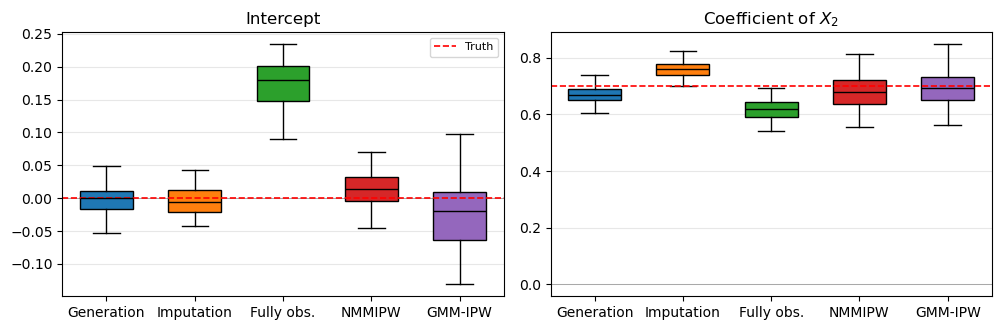

In [81]:
plot_coefficient_boxplots(coef_est, coef=coef_true, coef_names=["Intercept", "Coefficient of $X_2$"])
plt.savefig(
    f"results/regression_3_patterns_50_B_motexp_True_gaussian_mixture_0_Ycol_1.png",
    # f"results/regression_{n_pat}_patterns_{B}_B_motexp_{motexp}_{distr}_{Ycol}_Ycol_1.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

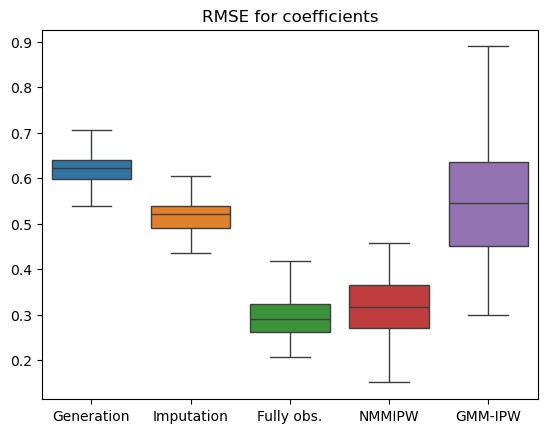

In [71]:
if coef_true != None:
    coef_true_np = coef_true.detach().numpy()
    rmse_coef = pd.DataFrame({method: [np.linalg.norm(c - coef_true_np) for c in coefs] for method, coefs in coef_est.items()})
    sns.boxplot(rmse_coef, showfliers=False)
    plt.xticks(ticks=methods, labels=[method_names[m] for m in methods])
    plt.title("RMSE for coefficients")
    plt.savefig(
    f"results/regression_{n_pat}_patterns_{B}_B_motexp_{motexp}_{distr}_{Ycol}_Ycol_RMSE.png",
    # f"results/regression_3_patterns_50_B_motexp_True_gaussian_mixture_0_Ycol_RMSE.png",
    dpi=300,
    bbox_inches="tight",
    )
    plt.show()

Text(0.5, 1.0, 'RMSE on test data')

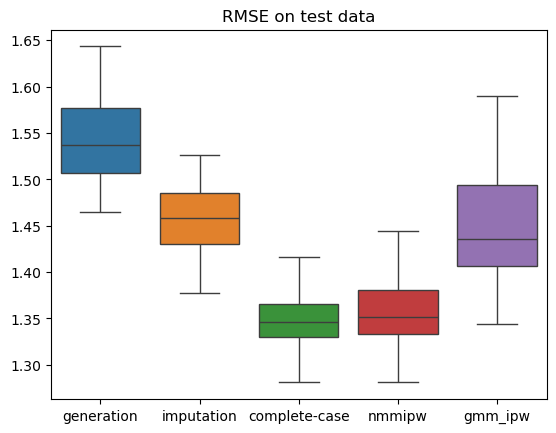

Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain


In [61]:
rmse = np.sqrt(pd.DataFrame(mse))
sns.boxplot(rmse, showfliers=False)
plt.title("RMSE on test data")
# plt.savefig("rmse.png")